# Module Nine Project

For the module nine project you are required to produce coding samples in accordance with the requirements in the project guidelines and rubric. This Notebook has been pre-created as a shell for your project submission.

Once your code is complete, you will download this notebook as an HTML file by clicking **File**, then **Download As**, then **HTML (.html)** from the Jupyter menu bar. Validate that your code and outputs are rendered in the html file before submission.

<div class="alert alert-block alert-danger">
    <span style="color:black"><b><i>Missing Blocks:</i></b> Ensure that you have clicked <b><mark>Run</mark></b> for all blocks before downloading as an HTML file or the block may be missing from your submission.</span>
</div>

### Data Source Information
Below are some example reputable data sources that you can use to collect your minimum of two data sets from:

- https://datasetsearch.research.google.com/
- https://www.kaggle.com/datasets
- https://data.gov/
- https://www.census.gov/data.html
- https://www.bls.gov/data/
- https://databank.worldbank.org/databases
- https://www.ncei.noaa.gov/access/search/index
- https://www.epa.gov/data
- https://www.pewresearch.org/tools-and-datasets/
- https://www.who.int/data/
- https://dataverse.harvard.edu/
- https://search.cdc.gov/search/?query=dataset&dpage=1
- https://data.fivethirtyeight.com/
- https://www.gdeltproject.org/data.html
- https://datahub.io/collections


***Note: this list is not all inclusive, if you have a reputable data set that you have collected, or would like to use, please ensure to upload the data. All data sets will need to be documented in your submission as to the source through the creation of a citation.***

<div class="alert alert-block alert-success">
    <span style="color:black"><b><i>To Begin:</i></b> replace each <b>data_file_#</b> entry sample data path with the path to your selected data sets.</span>
</div>

You are welcome to use more than two data sets, create an entry for each as applicable for each data set. Ensure that you create comments that provide citations for the data sets you have selected for use. When working through your submission, keep in mind that you will need to have choosen two separate groups of stakeholders to create your final visualizations.

In [1]:
# CS 540 - Module Nine Final Project
# Student: Justice Williamson
# Southern New Hampshire University
# Project: Exploring the Relationship Between
# Economic Development and Life Expectancy

# Dataset 1: GDP per capita (current US$)
# Source: World Bank, World Development Indicators
# Indicator: NY.GDP.PCAP.CD
# Last updated: November 11, 2026
# https://data.worldbank.org/indicator/NY.GDP.PCAP.CD

data_file_1 = "data/gdp_per_capita.csv"

# Dataset 2: Life expectancy at birth, total (years)
# Source: World Bank, World Development Indicators
# Indicator: SP.DYN.LE00.IN
# Last updated: November 11, 2026
# https://data.worldbank.org/indicator/SP.DYN.LE00.IN

data_file_2 = "data/life_expectancy.csv"

# Supplementary dataset: Country metadata
# Source: World Bank, World Development Indicators
# Provides geographic regions and income classifications.

data_file_3 = "data/country_metadata.csv"

# Verify that all required files exist
from pathlib import Path

for file in [data_file_1, data_file_2, data_file_3]:
    if Path(file).is_file():
        print(f"FOUND: {file}")
    else:
        print(f"MISSING: {file}")


FOUND: data/gdp_per_capita.csv
FOUND: data/life_expectancy.csv
FOUND: data/country_metadata.csv


## Installing Required Packages
If you have additional packages that you would like to use or install, add them to the **requirements.txt** file then run the next two blocks.

In [2]:
!pip install --upgrade pip

In [3]:
!pip install -r requirements.txt

## Import the Required Packages

In [4]:
# Import libraries for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Display visualizations directly in the notebook
%matplotlib inline

# Configure visualization appearance
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120

# Configure data display settings
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.2f}".format)

print("All required packages imported successfully.")


All required packages imported successfully.


## Loading the Data
Create entries to load your data for your submission.

In [5]:
# Load the World Bank datasets into pandas DataFrames

# Skip the first four rows containing source information
gdp_df = pd.read_csv(data_file_1, skiprows=4)
life_df = pd.read_csv(data_file_2, skiprows=4)

# Load the supplementary country metadata
metadata_df = pd.read_csv(data_file_3)

# Verify that the correct indicators were loaded
assert gdp_df["Indicator Code"].eq("NY.GDP.PCAP.CD").all()
assert life_df["Indicator Code"].eq("SP.DYN.LE00.IN").all()

# Verify the country metadata columns
required_columns = ["Country Code", "Region", "IncomeGroup"]
assert all(col in metadata_df.columns for col in required_columns)

# Display the dimensions of each dataset
print("DATASET LOADING RESULTS")
print("=" * 60)

print(f"GDP per capita: {gdp_df.shape[0]} rows, "
      f"{gdp_df.shape[1]} columns")

print(f"Life expectancy: {life_df.shape[0]} rows, "
      f"{life_df.shape[1]} columns")

print(f"Country metadata: {metadata_df.shape[0]} rows, "
      f"{metadata_df.shape[1]} columns")

print("\nAll three datasets loaded and validated successfully.")

# Preview the GDP per capita dataset
print("\nGDP PER CAPITA - FIRST 5 RECORDS")
display(gdp_df.head())

# Preview the life expectancy dataset
print("\nLIFE EXPECTANCY - FIRST 5 RECORDS")
display(life_df.head())

# Preview the country metadata
print("\nCOUNTRY METADATA - FIRST 5 RECORDS")
display(metadata_df.head())


DATASET LOADING RESULTS
GDP per capita: 266 rows, 71 columns
Life expectancy: 266 rows, 71 columns
Country metadata: 265 rows, 6 columns

All three datasets loaded and validated successfully.

GDP PER CAPITA - FIRST 5 RECORDS


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,GDP per capita (current US$),NY.GDP.PCAP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,"28,440.04","30,082.16","30,654.49","22,664.37","26,827.34","31,000.57","34,897.62","38,590.57",NaN,NaN
1,Africa Eastern and Southern,AFE,GDP per capita (current US$),NY.GDP.PCAP.CD,186.09,186.91,197.37,225.40,208.96,226.84,...,"1,529.92","1,553.62","1,508.03","1,351.50","1,560.89","1,675.90","1,571.13","1,628.23","1,722.39",NaN
2,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,525.47,491.34,496.60,510.79,356.50,357.26,413.76,416.87,NaN,NaN
3,Africa Western and Central,AFW,GDP per capita (current US$),NY.GDP.PCAP.CD,121.94,127.45,133.82,139.00,148.55,155.59,...,"1,577.20","1,723.11","2,219.41","2,034.44","2,116.94","2,143.07","1,846.25","1,416.23","1,600.06",NaN
4,Angola,AGO,GDP per capita (current US$),NY.GDP.PCAP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,"2,832.15","2,891.83","2,507.87","1,749.18","2,266.97","3,598.54","2,885.51","2,720.82","3,129.48",NaN



LIFE EXPECTANCY - FIRST 5 RECORDS


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,64.05,64.22,64.60,64.94,65.30,65.61,...,75.62,75.88,76.02,75.41,73.66,76.23,76.35,76.50,NaN,NaN
1,Africa Eastern and Southern,AFE,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,44.17,44.47,44.88,45.16,45.54,45.77,...,62.59,63.33,63.86,63.77,62.98,64.49,65.15,65.35,NaN,NaN
2,Afghanistan,AFG,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,32.80,33.29,33.76,34.20,34.67,35.12,...,62.41,62.44,62.94,61.45,60.42,65.62,66.03,66.29,NaN,NaN
3,Africa Western and Central,AFW,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,37.78,38.06,38.68,38.94,39.19,39.48,...,56.62,57.03,57.14,57.36,57.36,57.98,58.85,59.04,NaN,NaN
4,Angola,AGO,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,37.93,36.90,37.17,37.42,37.70,37.97,...,62.12,62.62,63.05,63.12,62.96,64.25,64.62,64.81,NaN,NaN



COUNTRY METADATA - FIRST 5 RECORDS


,Country Code,Region,IncomeGroup,SpecialNotes,TableName,Unnamed: 5
0,ABW,Latin America & Caribbean,High income,NaN,Aruba,NaN
1,AFE,NaN,NaN,"26 countries, stretching from the Red Sea in t...",Africa Eastern and Southern,NaN
2,AFG,Middle East & North Africa,Low income,The reporting period for national accounts dat...,Afghanistan,NaN
3,AFW,NaN,NaN,"22 countries, stretching from the westernmost ...",Africa Western and Central,NaN
4,AGO,Sub-Saharan Africa,Lower middle income,The World Bank systematically assesses the app...,Angola,NaN


## Examining the Data
Create entries to conduct exploratory data analysis to identify key data points to include relevant data from your two data sets while evaluating the quality of your choosen data.

In [6]:
# EXPLORATORY DATA ANALYSIS (EDA)
# Examine dataset structure, completeness, and quality.

print("EXPLORATORY DATA ANALYSIS")
print("=" * 70)

# Select the study period: 2000-2023
study_years = [str(year) for year in range(2000, 2024)]

# Verify that all selected years exist
assert all(year in gdp_df.columns for year in study_years)
assert all(year in life_df.columns for year in study_years)

print("\n1. STUDY PERIOD")
print("Selected years: 2000-2023")
print(f"Number of years: {len(study_years)}")

# Examine dataset structure
print("\n2. DATASET STRUCTURE")

structure_summary = pd.DataFrame({
    "Dataset": [
        "GDP per Capita",
        "Life Expectancy",
        "Country Metadata"
    ],
    "Rows": [
        len(gdp_df),
        len(life_df),
        len(metadata_df)
    ],
    "Columns": [
        gdp_df.shape[1],
        life_df.shape[1],
        metadata_df.shape[1]
    ],
    "Unique Country Codes": [
        gdp_df["Country Code"].nunique(),
        life_df["Country Code"].nunique(),
        metadata_df["Country Code"].nunique()
    ]
})

display(structure_summary)

# Evaluate missing values during the study period
print("\n3. MISSING DATA ANALYSIS")

missing_summary = pd.DataFrame({
    "GDP Missing Values":
        gdp_df[study_years].isna().sum(),
    "GDP Missing (%)":
        gdp_df[study_years].isna().mean() * 100,
    "Life Expectancy Missing Values":
        life_df[study_years].isna().sum(),
    "Life Expectancy Missing (%)":
        life_df[study_years].isna().mean() * 100
})

missing_summary.index.name = "Year"

display(missing_summary.round(2))

# Examine duplicate records
print("\n4. DUPLICATE RECORD ANALYSIS")

for name, dataset in [
    ("GDP per Capita", gdp_df),
    ("Life Expectancy", life_df),
    ("Country Metadata", metadata_df)
]:
    print(f"{name}:")
    print(f"  Duplicate rows: {dataset.duplicated().sum()}")
    print(f"  Duplicate country codes: "
          f"{dataset['Country Code'].duplicated().sum()}")

# Identify unnecessary empty columns
print("\n5. UNNECESSARY COLUMNS")

for name, dataset in [
    ("GDP per Capita", gdp_df),
    ("Life Expectancy", life_df),
    ("Country Metadata", metadata_df)
]:
    empty_columns = dataset.columns[
        dataset.isna().all()
    ].tolist()

    print(f"{name}: {empty_columns}")

# Identify countries and geographic aggregates
print("\n6. COUNTRY AND REGION CLASSIFICATIONS")

country_metadata = metadata_df[
    metadata_df["Region"].notna()
].copy()

print(f"Individual economies with assigned regions: "
      f"{len(country_metadata)}")

print(f"Metadata records without assigned regions: "
      f"{metadata_df['Region'].isna().sum()}")

# Compare country codes across datasets
valid_codes = set(country_metadata["Country Code"])

gdp_codes = set(gdp_df["Country Code"])
life_codes = set(life_df["Country Code"])

print(f"Economies represented in both datasets: "
      f"{len(valid_codes & gdp_codes & life_codes)}")

# Geographic region distribution
print("\n7. GEOGRAPHIC REGION DISTRIBUTION")
display(country_metadata["Region"].value_counts())

# Income classification distribution
print("\n8. INCOME GROUP DISTRIBUTION")
display(
    country_metadata["IncomeGroup"].value_counts(
        dropna=False
    )
)

# Calculate descriptive statistics for individual economies
print("\n9. DESCRIPTIVE STATISTICS FOR 2023")

gdp_2023 = gdp_df[
    gdp_df["Country Code"].isin(valid_codes)
]["2023"]

life_2023 = life_df[
    life_df["Country Code"].isin(valid_codes)
]["2023"]

statistics_2023 = pd.DataFrame({
    "GDP per Capita (USD)": gdp_2023.describe(),
    "Life Expectancy (Years)": life_2023.describe()
})

display(statistics_2023.round(2))

# Preliminary data quality assessment
print("\n10. PRELIMINARY DATA QUALITY ASSESSMENT")

print("""
Strengths:
- Both primary datasets originate from the World Bank.
- Both datasets contain standardized country codes.
- Both datasets cover the selected study period.
- Country metadata supports regional and income comparisons.

Limitations:
- Some historical observations are missing.
- Regional aggregates must be separated from individual economies.
- GDP is measured in current US dollars and is affected by
  inflation and exchange-rate changes.
- Income classifications reflect the downloaded metadata
  rather than historical classifications for each year.
- Statistical relationships do not establish causation.

Preprocessing Plan:
- Remove unnecessary columns.
- Exclude regional and global aggregate records.
- Reshape annual columns into individual year records.
- Merge datasets using country codes and years.
- Evaluate missing and invalid numerical values.
- Retain valid observations for comparative analysis.
""")

print("Exploratory data analysis completed successfully.")


EXPLORATORY DATA ANALYSIS

1. STUDY PERIOD
Selected years: 2000-2023
Number of years: 24

2. DATASET STRUCTURE


,Dataset,Rows,Columns,Unique Country Codes
0,GDP per Capita,266,71,266
1,Life Expectancy,266,71,266
2,Country Metadata,265,6,265



3. MISSING DATA ANALYSIS


,GDP Missing Values,GDP Missing (%),Life Expectancy Missing Values,Life Expectancy Missing (%)
Year,,,,
2000,14,5.26,1,0.38
2001,13,4.89,1,0.38
2002,9,3.38,1,0.38
2003,9,3.38,1,0.38
2004,9,3.38,1,0.38
2005,9,3.38,1,0.38
2006,8,3.01,1,0.38
2007,8,3.01,1,0.38
2008,7,2.63,1,0.38



4. DUPLICATE RECORD ANALYSIS
GDP per Capita:
  Duplicate rows: 0
  Duplicate country codes: 0
Life Expectancy:
  Duplicate rows: 0
  Duplicate country codes: 0
Country Metadata:
  Duplicate rows: 0
  Duplicate country codes: 0

5. UNNECESSARY COLUMNS
GDP per Capita: ['Unnamed: 70']
Life Expectancy: ['2025', 'Unnamed: 70']
Country Metadata: ['Unnamed: 5']

6. COUNTRY AND REGION CLASSIFICATIONS
Individual economies with assigned regions: 217
Metadata records without assigned regions: 48
Economies represented in both datasets: 217

7. GEOGRAPHIC REGION DISTRIBUTION


Region
Europe & Central Asia         58
Sub-Saharan Africa            48
Latin America & Caribbean     42
East Asia & Pacific           37
Middle East & North Africa    23
South Asia                     6
North America                  3
Name: count, dtype: int64


8. INCOME GROUP DISTRIBUTION


IncomeGroup
High income            86
Upper middle income    59
Lower middle income    47
Low income             25
Name: count, dtype: int64


9. DESCRIPTIVE STATISTICS FOR 2023


,GDP per Capita (USD),Life Expectancy (Years)
count,204.00,217.00
mean,"22,295.54",73.79
std,"33,559.35",7.12
min,249.80,54.46
25%,"2,945.93",68.48
50%,"7,862.03",74.55
75%,"30,638.40",79.59
max,"256,799.91",86.37



10. PRELIMINARY DATA QUALITY ASSESSMENT

Strengths:
- Both primary datasets originate from the World Bank.
- Both datasets contain standardized country codes.
- Both datasets cover the selected study period.
- Country metadata supports regional and income comparisons.

Limitations:
- Some historical observations are missing.
- Regional aggregates must be separated from individual economies.
- GDP is measured in current US dollars and is affected by
  inflation and exchange-rate changes.
- Income classifications reflect the downloaded metadata
  rather than historical classifications for each year.
- Statistical relationships do not establish causation.

Preprocessing Plan:
- Remove unnecessary columns.
- Exclude regional and global aggregate records.
- Reshape annual columns into individual year records.
- Merge datasets using country codes and years.
- Evaluate missing and invalid numerical values.
- Retain valid observations for comparative analysis.

Exploratory data analysis compl

## Data Preprocessing Techniques
Create entries to clean and blend your data sets as applicable consolidating the two or more data sets into a single collection for inclusion into your visualizations.

In [7]:
# DATA PREPROCESSING AND DATASET BLENDING
# CS 540 - Module Nine Final Project

print("DATA PREPROCESSING AND DATASET BLENDING")
print("=" * 70)

# 1. Select relevant columns and individual economies

print("\n1. SELECTING RELEVANT DATA")

selected_columns = [
    "Country Name",
    "Country Code"
] + study_years

gdp_clean = gdp_df.loc[
    gdp_df["Country Code"].isin(valid_codes),
    selected_columns
].copy()

life_clean = life_df.loc[
    life_df["Country Code"].isin(valid_codes),
    selected_columns
].copy()

metadata_clean = country_metadata[
    ["Country Code", "Region", "IncomeGroup"]
].copy()

print(f"GDP economy records retained: {len(gdp_clean)}")
print(f"Life expectancy economy records retained: {len(life_clean)}")
print(f"Country metadata records retained: {len(metadata_clean)}")

# 2. Reshape datasets from wide to long format

print("\n2. RESHAPING DATASETS")

gdp_long = gdp_clean.melt(
    id_vars=["Country Name", "Country Code"],
    value_vars=study_years,
    var_name="Year",
    value_name="GDP_per_Capita"
)

life_long = life_clean.melt(
    id_vars=["Country Code"],
    value_vars=study_years,
    var_name="Year",
    value_name="Life_Expectancy"
)

# Convert years to integers

gdp_long["Year"] = gdp_long["Year"].astype(int)
life_long["Year"] = life_long["Year"].astype(int)

print(f"GDP observations: {len(gdp_long):,}")
print(f"Life expectancy observations: {len(life_long):,}")

# 3. Standardize numerical data types

print("\n3. STANDARDIZING DATA TYPES")

gdp_long["GDP_per_Capita"] = pd.to_numeric(
    gdp_long["GDP_per_Capita"],
    errors="coerce"
)

life_long["Life_Expectancy"] = pd.to_numeric(
    life_long["Life_Expectancy"],
    errors="coerce"
)

print("Years converted to integers.")
print("GDP and life expectancy converted to numerical values.")

# 4. Blend the two primary datasets

print("\n4. MERGING GDP AND LIFE EXPECTANCY DATA")

merged_df = pd.merge(
    gdp_long,
    life_long,
    on=["Country Code", "Year"],
    how="outer",
    validate="one_to_one",
    indicator=True
)

print("Merge matching results:")
display(merged_df["_merge"].value_counts())

merged_df = merged_df[
    merged_df["_merge"] == "both"
].drop(columns="_merge").copy()

print(f"Matched country-year records: {len(merged_df):,}")

# 5. Integrate country metadata

print("\n5. INTEGRATING COUNTRY METADATA")

merged_df = pd.merge(
    merged_df,
    metadata_clean,
    on="Country Code",
    how="left",
    validate="many_to_one"
)

print(f"Records after metadata integration: {len(merged_df):,}")

# 6. Evaluate missing and invalid observations

print("\n6. EVALUATING MISSING AND INVALID VALUES")

records_before = len(merged_df)

print("Missing values before cleaning:")
display(merged_df.isna().sum())

invalid_gdp = (
    merged_df["GDP_per_Capita"].notna()
    & (
        (merged_df["GDP_per_Capita"] <= 0)
        | ~np.isfinite(merged_df["GDP_per_Capita"])
    )
)

invalid_life = (
    merged_df["Life_Expectancy"].notna()
    & (
        (merged_df["Life_Expectancy"] <= 0)
        | (merged_df["Life_Expectancy"] > 120)
        | ~np.isfinite(merged_df["Life_Expectancy"])
    )
)

print(f"Invalid GDP observations: {invalid_gdp.sum()}")
print(f"Invalid life expectancy observations: {invalid_life.sum()}")

# Mark invalid observations as missing

merged_df.loc[
    invalid_gdp, "GDP_per_Capita"
] = np.nan

merged_df.loc[
    invalid_life, "Life_Expectancy"
] = np.nan

# 7. Remove incomplete observations

print("\n7. REMOVING INCOMPLETE OBSERVATIONS")

final_df = merged_df.dropna(
    subset=[
        "GDP_per_Capita",
        "Life_Expectancy",
        "Region",
        "IncomeGroup"
    ]
).copy()

records_removed = records_before - len(final_df)

retention_rate = (
    len(final_df) / records_before
) * 100

print(f"Records before cleaning: {records_before:,}")
print(f"Records removed: {records_removed:,}")
print(f"Records retained: {len(final_df):,}")
print(f"Data retention rate: {retention_rate:.2f}%")

# 8. Create derived attributes

print("\n8. CREATING DERIVED ATTRIBUTES")

# Logarithmic transformation reduces GDP skewness
# and supports clearer country-level comparisons.

final_df["Log_GDP"] = np.log10(
    final_df["GDP_per_Capita"]
)

# Sort records for consistent chronological analysis

final_df = final_df.sort_values(
    ["Country Code", "Year"]
).reset_index(drop=True)

print("Logarithmic GDP attribute created.")
print("Records sorted by country code and year.")

# 9. Validate the integrated dataset

print("\n9. FINAL DATA QUALITY VALIDATION")

assert not final_df.duplicated(
    subset=["Country Code", "Year"]
).any()

assert final_df.isna().sum().sum() == 0

assert final_df["GDP_per_Capita"].gt(0).all()

assert final_df["Life_Expectancy"].between(
    0, 120, inclusive="right"
).all()

assert final_df["Year"].between(2000, 2023).all()

assert np.isfinite(final_df["Log_GDP"]).all()

print("Duplicate country-year records: 0")
print("Missing values: 0")
print("Invalid numerical observations: 0")
print("Study period validated: 2000-2023")

# 10. Display the final dataset

print("\n10. FINAL INTEGRATED DATASET")

print(f"Total records: {len(final_df):,}")
print(f"Total columns: {final_df.shape[1]}")
print(f"Unique economies: {final_df['Country Code'].nunique()}")
print(f"Geographic regions: {final_df['Region'].nunique()}")
print(f"Income groups: {final_df['IncomeGroup'].nunique()}")
print(f"Years represented: {final_df['Year'].nunique()}")

display(final_df.head(10))

# 11. Create the detailed 2023 analysis dataset

print("\n11. DETAILED ANALYSIS DATASET - 2023")

df_2023 = final_df[
    final_df["Year"] == 2023
].copy()

print(f"2023 matched observations: {len(df_2023)}")

display(
    df_2023[
        ["GDP_per_Capita", "Life_Expectancy"]
    ].describe().round(2)
)

# 12. Evaluate annual data coverage

print("\n12. ANNUAL DATA COVERAGE")

annual_coverage = final_df.groupby(
    "Year"
)["Country Code"].nunique().to_frame(
    "Economies with Complete Data"
)

annual_coverage["Coverage (%)"] = (
    annual_coverage["Economies with Complete Data"]
    / len(valid_codes) * 100
)

display(annual_coverage.round(2))

# 13. Save the integrated dataset

print("\n13. EXPORTING THE CLEANED DATASET")

output_path = Path("data/output")
output_path.mkdir(parents=True, exist_ok=True)

final_df.to_csv(
    output_path / "integrated_gdp_life_expectancy.csv",
    index=False
)

df_2023.to_csv(
    output_path / "gdp_life_expectancy_2023.csv",
    index=False
)

print("Integrated dataset saved successfully.")
print("2023 analysis dataset saved successfully.")

print("""
Preprocessing Summary:
- Relevant attributes were selected.
- Regional aggregates were excluded using country metadata.
- Annual columns were converted into country-year records.
- GDP and life expectancy datasets were merged.
- Region and income classifications were integrated.
- Missing and invalid observations were excluded.
- A logarithmic GDP attribute was created.
- The integrated dataset passed quality validation.

Limitations:
- Complete-case filtering may introduce selection bias.
- Annual country coverage may vary.
- Income groups reflect the downloaded metadata rather
  than historical annual classifications.
""")

print("Data preprocessing and blending completed successfully.")


DATA PREPROCESSING AND DATASET BLENDING

1. SELECTING RELEVANT DATA
GDP economy records retained: 217
Life expectancy economy records retained: 217
Country metadata records retained: 217

2. RESHAPING DATASETS
GDP observations: 5,208
Life expectancy observations: 5,208

3. STANDARDIZING DATA TYPES
Years converted to integers.
GDP and life expectancy converted to numerical values.

4. MERGING GDP AND LIFE EXPECTANCY DATA
Merge matching results:


_merge
both          5208
left_only        0
right_only       0
Name: count, dtype: int64

Matched country-year records: 5,208

5. INTEGRATING COUNTRY METADATA
Records after metadata integration: 5,208

6. EVALUATING MISSING AND INVALID VALUES
Missing values before cleaning:


Country Name         0
Country Code         0
Year                 0
GDP_per_Capita     166
Life_Expectancy      0
Region               0
IncomeGroup          0
dtype: int64

Invalid GDP observations: 0
Invalid life expectancy observations: 0

7. REMOVING INCOMPLETE OBSERVATIONS
Records before cleaning: 5,208
Records removed: 166
Records retained: 5,042
Data retention rate: 96.81%

8. CREATING DERIVED ATTRIBUTES
Logarithmic GDP attribute created.
Records sorted by country code and year.

9. FINAL DATA QUALITY VALIDATION
Duplicate country-year records: 0
Missing values: 0
Invalid numerical observations: 0
Study period validated: 2000-2023

10. FINAL INTEGRATED DATASET
Total records: 5,042
Total columns: 8
Unique economies: 214
Geographic regions: 7
Income groups: 4
Years represented: 24


,Country Name,Country Code,Year,GDP_per_Capita,Life_Expectancy,Region,IncomeGroup,Log_GDP
0,Aruba,ABW,2000,"20,681.02",72.94,Latin America & Caribbean,High income,4.32
1,Aruba,ABW,2001,"20,740.13",73.04,Latin America & Caribbean,High income,4.32
2,Aruba,ABW,2002,"21,307.25",73.14,Latin America & Caribbean,High income,4.33
3,Aruba,ABW,2003,"21,949.49",73.24,Latin America & Caribbean,High income,4.34
4,Aruba,ABW,2004,"23,700.63",73.22,Latin America & Caribbean,High income,4.37
5,Aruba,ABW,2005,"24,171.84",73.42,Latin America & Caribbean,High income,4.38
6,Aruba,ABW,2006,"24,845.66",73.50,Latin America & Caribbean,High income,4.40
7,Aruba,ABW,2007,"26,736.31",73.64,Latin America & Caribbean,High income,4.43
8,Aruba,ABW,2008,"28,171.91",73.78,Latin America & Caribbean,High income,4.45
9,Aruba,ABW,2009,"25,134.77",73.97,Latin America & Caribbean,High income,4.40



11. DETAILED ANALYSIS DATASET - 2023
2023 matched observations: 204


,GDP_per_Capita,Life_Expectancy
count,204.00,204.00
mean,"22,295.54",73.74
std,"33,559.35",7.16
min,249.80,54.46
25%,"2,945.93",68.14
50%,"7,862.03",74.52
75%,"30,638.40",79.60
max,"256,799.91",86.37



12. ANNUAL DATA COVERAGE


,Economies with Complete Data,Coverage (%)
Year,,
2000,204,94.01
2001,205,94.47
2002,209,96.31
2003,209,96.31
2004,209,96.31
2005,209,96.31
2006,210,96.77
2007,210,96.77
2008,211,97.24



13. EXPORTING THE CLEANED DATASET
Integrated dataset saved successfully.
2023 analysis dataset saved successfully.

Preprocessing Summary:
- Relevant attributes were selected.
- Regional aggregates were excluded using country metadata.
- Annual columns were converted into country-year records.
- GDP and life expectancy datasets were merged.
- Region and income classifications were integrated.
- Missing and invalid observations were excluded.
- A logarithmic GDP attribute was created.
- The integrated dataset passed quality validation.

Limitations:
- Complete-case filtering may introduce selection bias.
- Annual country coverage may vary.
- Income groups reflect the downloaded metadata rather
  than historical annual classifications.

Data preprocessing and blending completed successfully.


## Data Visualizations
Create entries to visualize your data using appropriate visualization types to reveal key trends within the data collection. Integrate multiple data attributes into visualizations using appropriate techniques to derive key insights from your visualizations. In your data visualizations, you will use multi-level data modeling practices to refine your visualizations. Your visualizations should include a high-level visualization that provides a broad overview of the data for one of your two stakeholders, as well as a detailed, insight-focused visualization that highlights the key findings for the other of your two stakeholders.

DATA VISUALIZATIONS AND KEY INSIGHTS

AUDIENCE ONE: EXECUTIVE LEADERSHIP
High-level strategic visualizations

FIGURE 1: LIFE EXPECTANCY OVER TIME


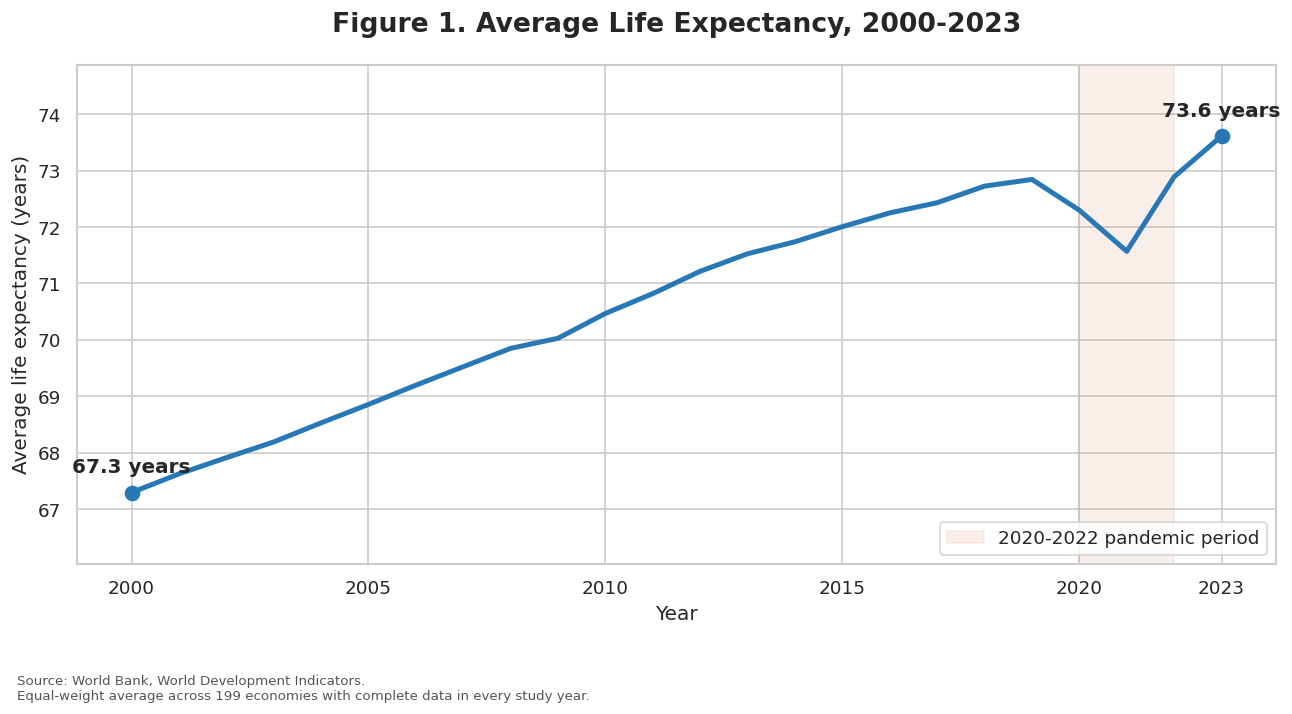

Economies in consistent historical sample: 199
Average life expectancy in 2000: 67.29 years
Average life expectancy in 2023: 73.61 years
Change between 2000 and 2023: +6.32 years
Insight: The line chart communicates long-term changes using a consistent group of economies.

FIGURE 2: LIFE EXPECTANCY BY INCOME GROUP


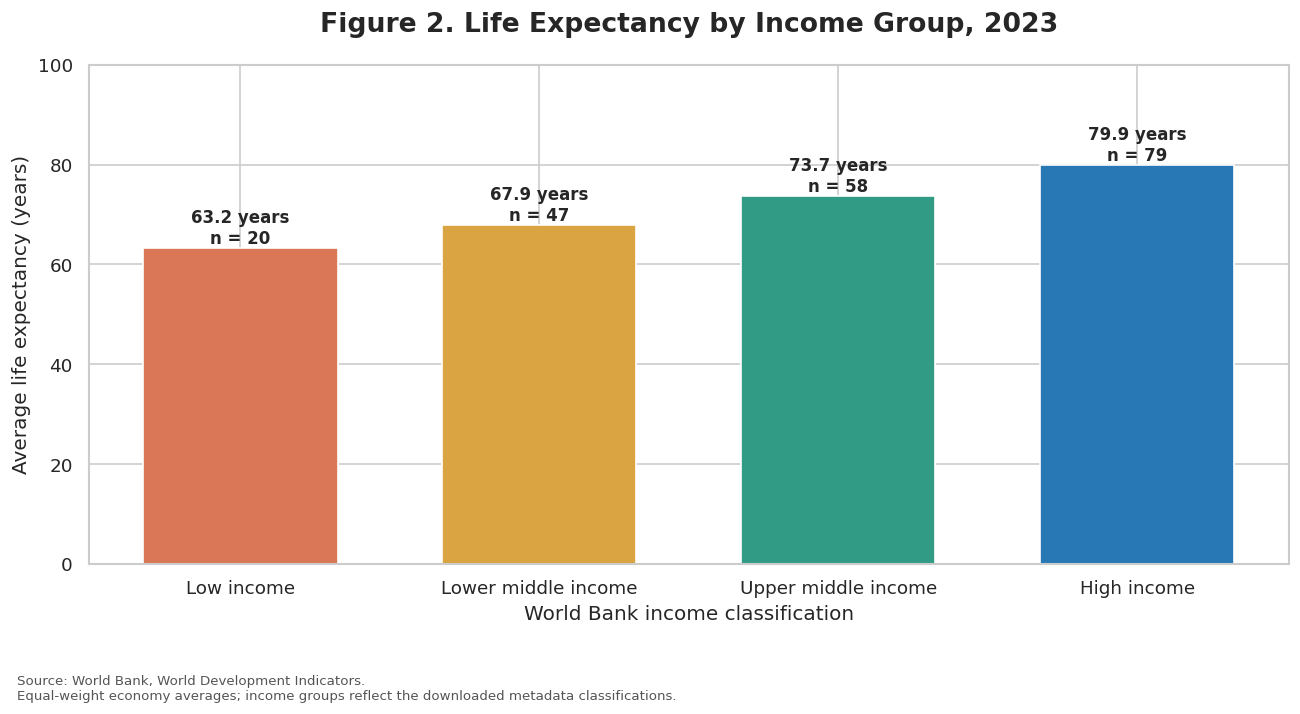

,Average_Life_Expectancy,Median_GDP,Economies
IncomeGroup,,,
Low income,63.19,777.81,20
Lower middle income,67.91,"2,383.90",47
Upper middle income,73.70,"7,072.76",58
High income,79.91,"36,623.71",79


High-income versus low-income life expectancy gap: 16.72 years
Insight: Income-group comparisons highlight differences that can guide further investigation and strategic resource prioritization.

AUDIENCE TWO: RESEARCH AND DATA ANALYSTS
Detailed analytical visualizations

FIGURE 3: GDP PER CAPITA VS LIFE EXPECTANCY


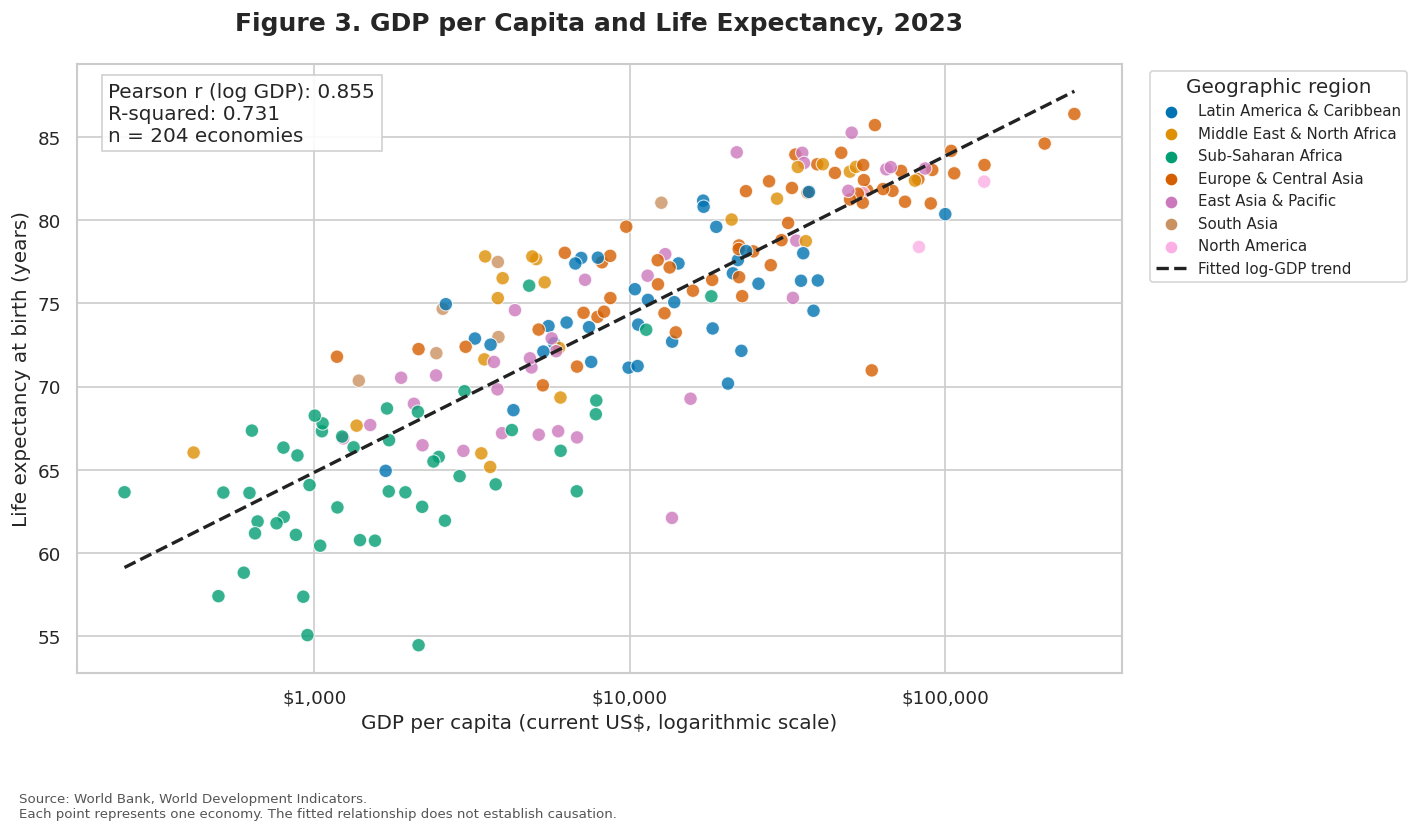

Pearson correlation (raw GDP): 0.6204
Pearson correlation (log GDP): 0.8551
Spearman rank correlation: 0.8650
Regression R-squared: 0.7313
Regression slope: 9.4989
Log-GDP correlation p-value: 1.503e-59
Insight: The logarithmic scale reduces visual compression caused by large differences in GDP and reveals the relationship more clearly.

FIGURE 4: REGIONAL ECONOMIC AND HEALTH COMPARISONS


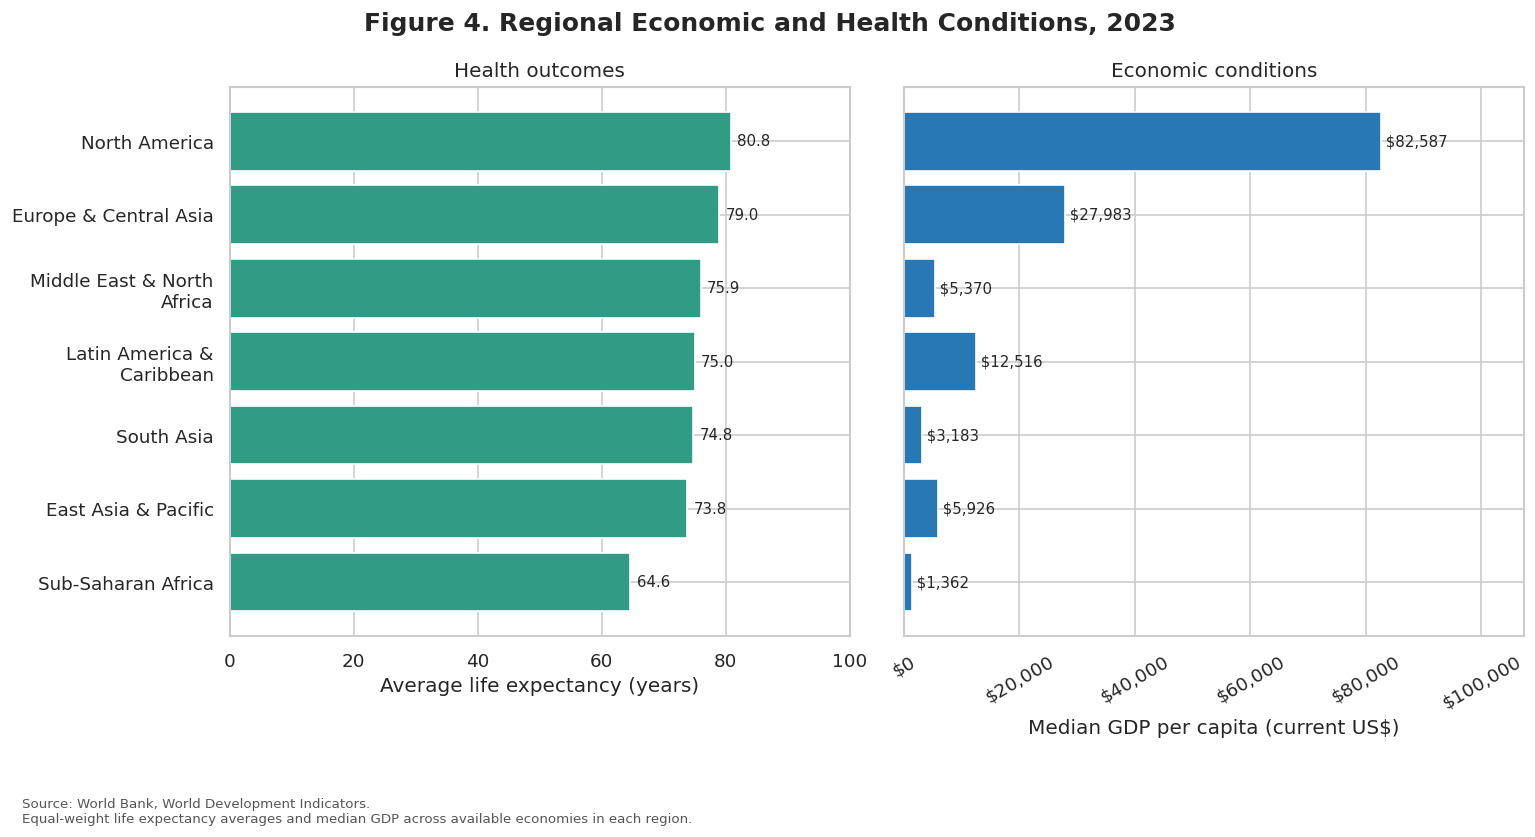

,Average_Life_Expectancy,Median_GDP,Economies
Region,,,
Sub-Saharan Africa,64.62,"1,362.45",46
East Asia & Pacific,73.76,"5,926.21",33
South Asia,74.75,"3,183.22",6
Latin America & Caribbean,74.99,"12,515.56",38
Middle East & North Africa,75.93,"5,370.48",21
Europe & Central Asia,78.97,"27,983.37",57
North America,80.77,"82,586.78",3


Highest regional average life expectancy: North America
Lowest regional average life expectancy: Sub-Saharan Africa
Insight: Regional comparisons provide geographic context while avoiding misleading comparisons between GDP and life expectancy on the same scale.

FIGURE 5: CORRELATION HEATMAP


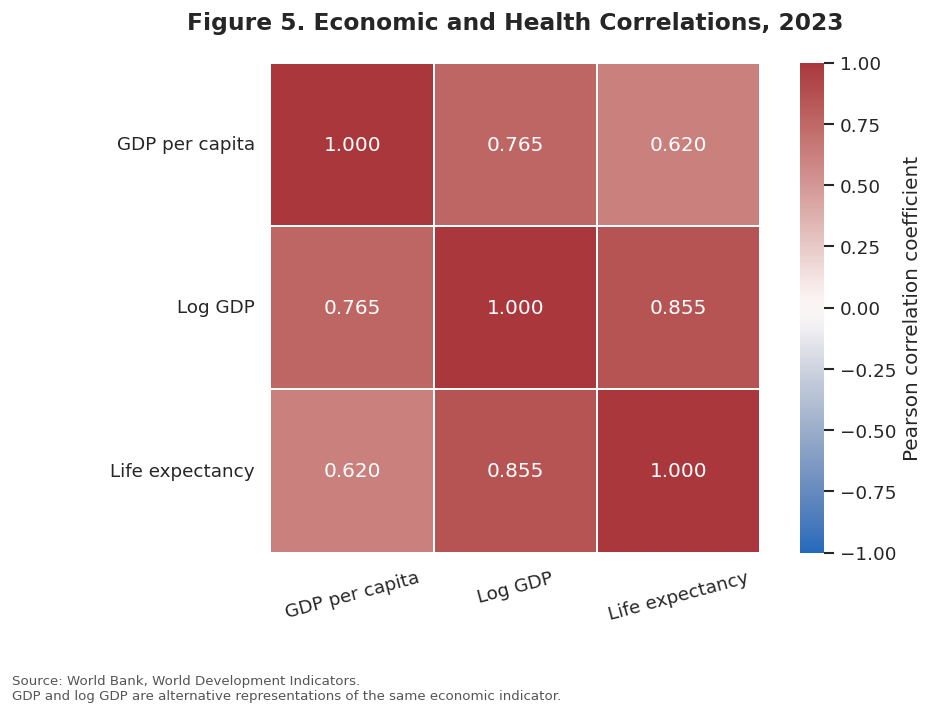

,GDP per capita,Log GDP,Life expectancy
GDP per capita,1.00,0.77,0.62
Log GDP,0.77,1.00,0.85
Life expectancy,0.62,0.85,1.00


Insight: The heatmap allows analysts to compare the relationship between life expectancy and both representations of GDP.

FIGURE 6: COUNTRY-LEVEL OUTLIER ANALYSIS


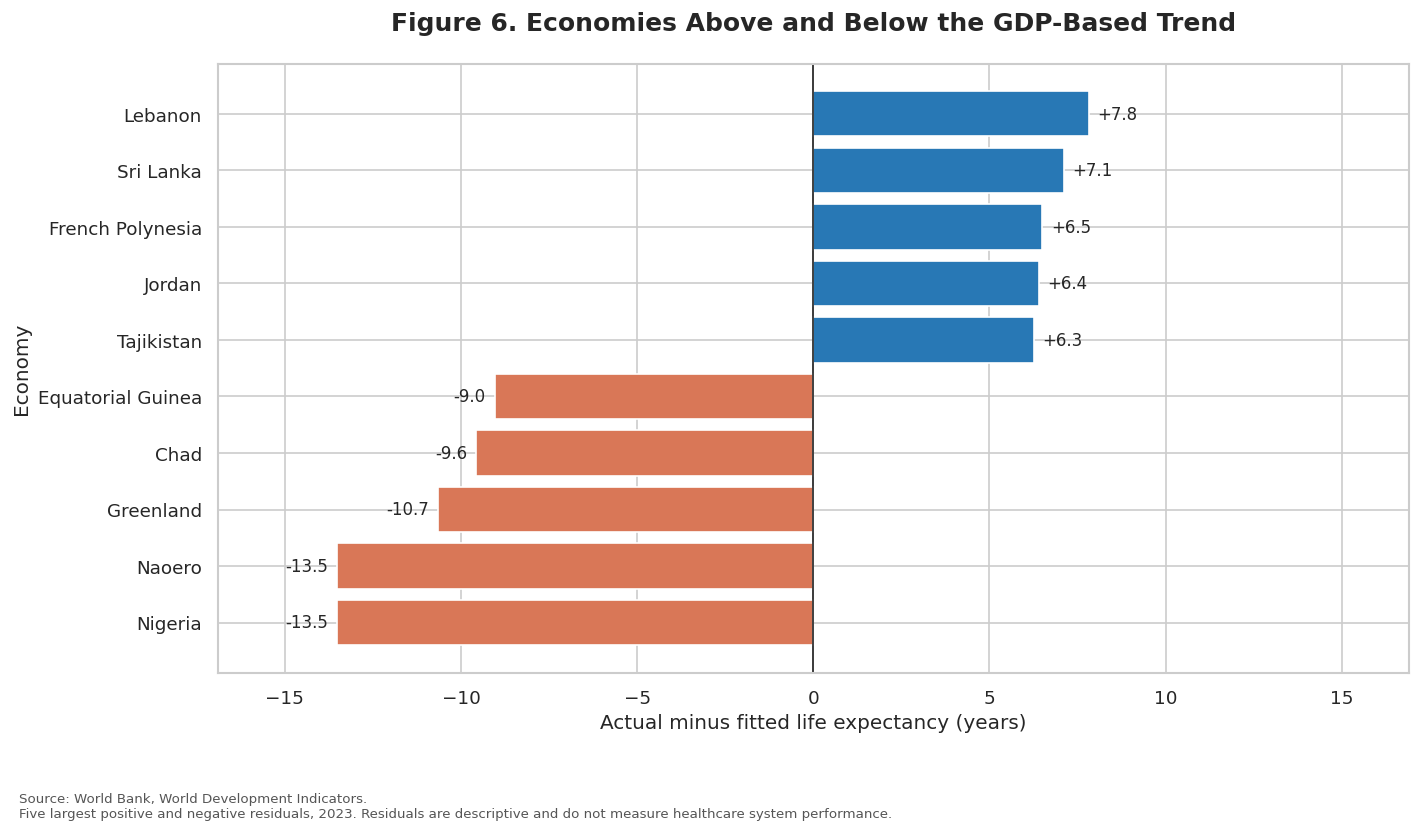

,Country Name,Region,GDP_per_Capita,Life_Expectancy,Predicted_Life_Expectancy,Life_Expectancy_Residual
3356,Nigeria,Sub-Saharan Africa,"2,138.76",54.46,67.99,-13.53
3476,Naoero,East Asia & Pacific,"13,602.64",62.11,75.62,-13.51
1846,Greenland,Europe & Central Asia,"58,498.97",70.97,81.64,-10.66
4409,Chad,Sub-Saharan Africa,949.99,55.07,64.64,-9.57
1774,Equatorial Guinea,Sub-Saharan Africa,"6,788.35",63.71,72.75,-9.04
4481,Tajikistan,Europe & Central Asia,"1,178.48",71.79,65.53,6.26
2299,Jordan,Middle East & North Africa,"4,906.24",77.81,71.41,6.40
3812,French Polynesia,East Asia & Pacific,"21,832.28",84.07,77.57,6.50
2683,Sri Lanka,South Asia,"3,815.42",77.48,70.37,7.11
2563,Lebanon,Middle East & North Africa,"3,477.72",77.82,69.99,7.82


Insight: Economies with large deviations from the fitted trend may warrant further research into social, environmental, and healthcare factors.

MULTI-LEVEL DATA MODELING SUMMARY

Level 1 - High-Level Strategic Overview:
- Figure 1 summarizes historical changes in life expectancy.
- Figure 2 compares average outcomes by income classification.
- Simple labels and direct comparisons support executive decisions.

Level 2 - Detailed Analytical Investigation:
- Figure 3 combines GDP, life expectancy, geographic region,
  and a fitted statistical relationship.
- Figure 4 compares regional economic and health indicators.
- Figure 5 evaluates numerical correlations.
- Figure 6 identifies economies that deviate from the fitted trend.

The two levels use the same integrated dataset but present
information at different levels of detail to match the
needs of each stakeholder audience.


FINAL QUANTITATIVE FINDINGS
Cleaned country-year observations: 5,042
Economies across study period: 214
Data ret

In [8]:
# DATA VISUALIZATIONS AND MULTI-LEVEL DATA MODELING
# CS 540 - Module Nine Final Project
# Student: Justice Williamson

from matplotlib.ticker import FuncFormatter
import textwrap

print("DATA VISUALIZATIONS AND KEY INSIGHTS")
print("=" * 70)

# Create a folder for exported visualizations

visualization_path = Path("data/output/visualizations")
visualization_path.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

# Consistent color scheme for income groups

income_order = [
    "Low income",
    "Lower middle income",
    "Upper middle income",
    "High income"
]

income_colors = {
    "Low income": "#D97757",
    "Lower middle income": "#D9A441",
    "Upper middle income": "#319B86",
    "High income": "#2878B5"
}

# Function to save and display figures

def save_figure(fig, filename, note=""):
    source = (
        "Source: World Bank, World Development Indicators."
    )

    if note:
        source += "\n" + note

    fig.text(
        0.02, 0.015,
        source,
        fontsize=8,
        color="#555555"
    )

    fig.tight_layout(rect=[0, 0.09, 1, 1])

    fig.savefig(
        visualization_path / filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)


# =====================================================
# AUDIENCE ONE: EXECUTIVE LEADERSHIP
# =====================================================

print("\nAUDIENCE ONE: EXECUTIVE LEADERSHIP")
print("High-level strategic visualizations")


# FIGURE 1: LIFE EXPECTANCY TRENDS

print("\nFIGURE 1: LIFE EXPECTANCY OVER TIME")

# Use the same economies across all 24 years
# to reduce changes caused by sample composition.

complete_codes = final_df.groupby(
    "Country Code"
)["Year"].nunique()

complete_codes = complete_codes[
    complete_codes == len(study_years)
].index

balanced_df = final_df[
    final_df["Country Code"].isin(complete_codes)
].copy()

annual_summary = balanced_df.groupby(
    "Year"
).agg(
    Average_Life_Expectancy=("Life_Expectancy", "mean"),
    Median_GDP=("GDP_per_Capita", "median"),
    Economies=("Country Code", "nunique")
).reset_index()

first_year = annual_summary.iloc[0]
last_year = annual_summary.iloc[-1]

life_change = (
    last_year["Average_Life_Expectancy"]
    - first_year["Average_Life_Expectancy"]
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    annual_summary["Year"],
    annual_summary["Average_Life_Expectancy"],
    color="#2878B5",
    linewidth=3
)

ax.scatter(
    [first_year["Year"], last_year["Year"]],
    [
        first_year["Average_Life_Expectancy"],
        last_year["Average_Life_Expectancy"]
    ],
    color="#2878B5",
    s=70,
    zorder=5
)

for row in [first_year, last_year]:
    ax.annotate(
        f"{row['Average_Life_Expectancy']:.1f} years",
        (
            row["Year"],
            row["Average_Life_Expectancy"]
        ),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax.axvspan(
    2020, 2022,
    color="#D97757",
    alpha=0.12,
    label="2020-2022 pandemic period"
)

ax.set_title(
    "Figure 1. Average Life Expectancy, 2000-2023",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Year")
ax.set_ylabel("Average life expectancy (years)")

ax.set_xticks(
    [2000, 2005, 2010, 2015, 2020, 2023]
)

ax.margins(y=0.20)
ax.legend(loc="lower right")

save_figure(
    fig,
    "figure_1_life_expectancy_trends.png",
    f"Equal-weight average across {len(complete_codes)} "
    "economies with complete data in every study year."
)

print(f"Economies in consistent historical sample: "
      f"{len(complete_codes)}")

print(f"Average life expectancy in 2000: "
      f"{first_year['Average_Life_Expectancy']:.2f} years")

print(f"Average life expectancy in 2023: "
      f"{last_year['Average_Life_Expectancy']:.2f} years")

print(f"Change between 2000 and 2023: "
      f"{life_change:+.2f} years")

print(
    "Insight: The line chart communicates long-term "
    "changes using a consistent group of economies."
)


# FIGURE 2: LIFE EXPECTANCY BY INCOME GROUP

print("\nFIGURE 2: LIFE EXPECTANCY BY INCOME GROUP")

income_summary = df_2023.groupby(
    "IncomeGroup"
).agg(
    Average_Life_Expectancy=("Life_Expectancy", "mean"),
    Median_GDP=("GDP_per_Capita", "median"),
    Economies=("Country Code", "nunique")
).reindex(income_order)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    income_summary.index,
    income_summary["Average_Life_Expectancy"],
    color=[income_colors[g] for g in income_order],
    width=0.65
)

for bar, (group, row) in zip(
    bars, income_summary.iterrows()
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{row['Average_Life_Expectancy']:.1f} years\n"
        f"n = {int(row['Economies'])}",
        ha="center",
        fontweight="bold",
        fontsize=10
    )

ax.set_title(
    "Figure 2. Life Expectancy by Income Group, 2023",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("World Bank income classification")
ax.set_ylabel("Average life expectancy (years)")
ax.set_ylim(0, 100)

save_figure(
    fig,
    "figure_2_income_group_comparison.png",
    "Equal-weight economy averages; income groups reflect "
    "the downloaded metadata classifications."
)

display(income_summary.round(2))

income_gap = (
    income_summary.loc[
        "High income", "Average_Life_Expectancy"
    ]
    - income_summary.loc[
        "Low income", "Average_Life_Expectancy"
    ]
)

print(f"High-income versus low-income "
      f"life expectancy gap: {income_gap:.2f} years")

print(
    "Insight: Income-group comparisons highlight "
    "differences that can guide further investigation "
    "and strategic resource prioritization."
)


# =====================================================
# AUDIENCE TWO: RESEARCH AND DATA ANALYSTS
# =====================================================

print("\nAUDIENCE TWO: RESEARCH AND DATA ANALYSTS")
print("Detailed analytical visualizations")


# FIGURE 3: GDP AND LIFE EXPECTANCY RELATIONSHIP

print("\nFIGURE 3: GDP PER CAPITA VS LIFE EXPECTANCY")

# Calculate statistical relationships

raw_correlation, raw_p = stats.pearsonr(
    df_2023["GDP_per_Capita"],
    df_2023["Life_Expectancy"]
)

log_correlation, log_p = stats.pearsonr(
    df_2023["Log_GDP"],
    df_2023["Life_Expectancy"]
)

spearman_correlation, spearman_p = stats.spearmanr(
    df_2023["GDP_per_Capita"],
    df_2023["Life_Expectancy"]
)

# Fit a linear model using logarithmic GDP

regression = stats.linregress(
    df_2023["Log_GDP"],
    df_2023["Life_Expectancy"]
)

x_log = np.linspace(
    df_2023["Log_GDP"].min(),
    df_2023["Log_GDP"].max(),
    200
)

y_predicted = (
    regression.intercept
    + regression.slope * x_log
)

fig, ax = plt.subplots(figsize=(12, 7))

sns.scatterplot(
    data=df_2023,
    x="GDP_per_Capita",
    y="Life_Expectancy",
    hue="Region",
    palette="colorblind",
    s=65,
    alpha=0.80,
    ax=ax
)

ax.plot(
    10 ** x_log,
    y_predicted,
    color="#222222",
    linestyle="--",
    linewidth=2,
    label="Fitted log-GDP trend"
)

ax.set_xscale("log")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x:,.0f}")
)

ax.set_title(
    "Figure 3. GDP per Capita and Life Expectancy, 2023",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "GDP per capita (current US$, logarithmic scale)"
)

ax.set_ylabel("Life expectancy at birth (years)")

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9,
    title="Geographic region"
)

ax.text(
    0.03, 0.97,
    f"Pearson r (log GDP): {log_correlation:.3f}\n"
    f"R-squared: {regression.rvalue ** 2:.3f}\n"
    f"n = {len(df_2023)} economies",
    transform=ax.transAxes,
    va="top",
    bbox=dict(
        facecolor="white",
        edgecolor="#CCCCCC",
        alpha=0.9
    )
)

save_figure(
    fig,
    "figure_3_gdp_life_expectancy_scatter.png",
    "Each point represents one economy. "
    "The fitted relationship does not establish causation."
)

print(f"Pearson correlation (raw GDP): "
      f"{raw_correlation:.4f}")

print(f"Pearson correlation (log GDP): "
      f"{log_correlation:.4f}")

print(f"Spearman rank correlation: "
      f"{spearman_correlation:.4f}")

print(f"Regression R-squared: "
      f"{regression.rvalue ** 2:.4f}")

print(f"Regression slope: {regression.slope:.4f}")

print(f"Log-GDP correlation p-value: {log_p:.3e}")

print(
    "Insight: The logarithmic scale reduces visual "
    "compression caused by large differences in GDP "
    "and reveals the relationship more clearly."
)


# FIGURE 4: REGIONAL COMPARISONS

print("\nFIGURE 4: REGIONAL ECONOMIC AND HEALTH COMPARISONS")

region_summary = df_2023.groupby(
    "Region"
).agg(
    Average_Life_Expectancy=("Life_Expectancy", "mean"),
    Median_GDP=("GDP_per_Capita", "median"),
    Economies=("Country Code", "nunique")
).sort_values("Average_Life_Expectancy")

region_labels = [
    textwrap.fill(region, width=23)
    for region in region_summary.index
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 7),
    sharey=True
)

positions = np.arange(len(region_summary))

axes[0].barh(
    positions,
    region_summary["Average_Life_Expectancy"],
    color="#319B86"
)

axes[0].set_yticks(positions)
axes[0].set_yticklabels(region_labels)

axes[0].set_xlabel("Average life expectancy (years)")
axes[0].set_title("Health outcomes")
axes[0].set_xlim(0, 100)

for i, value in enumerate(
    region_summary["Average_Life_Expectancy"]
):
    axes[0].text(
        value + 1,
        i,
        f"{value:.1f}",
        va="center",
        fontsize=9
    )

axes[1].barh(
    positions,
    region_summary["Median_GDP"],
    color="#2878B5"
)

axes[1].set_xlabel("Median GDP per capita (current US$)")
axes[1].set_title("Economic conditions")

axes[1].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x:,.0f}")
)

axes[1].set_xlim(
    0,
    region_summary["Median_GDP"].max() * 1.30
)

axes[1].tick_params(axis="x", rotation=30)

for i, value in enumerate(
    region_summary["Median_GDP"]
):
    axes[1].text(
        value,
        i,
        f" ${value:,.0f}",
        va="center",
        fontsize=9
    )

fig.suptitle(
    "Figure 4. Regional Economic and Health Conditions, 2023",
    fontsize=15,
    fontweight="bold"
)

save_figure(
    fig,
    "figure_4_regional_comparisons.png",
    "Equal-weight life expectancy averages and median "
    "GDP across available economies in each region."
)

display(region_summary.round(2))

print(
    f"Highest regional average life expectancy: "
    f"{region_summary['Average_Life_Expectancy'].idxmax()}"
)

print(
    f"Lowest regional average life expectancy: "
    f"{region_summary['Average_Life_Expectancy'].idxmin()}"
)

print(
    "Insight: Regional comparisons provide geographic "
    "context while avoiding misleading comparisons "
    "between GDP and life expectancy on the same scale."
)


# FIGURE 5: CORRELATION HEATMAP

print("\nFIGURE 5: CORRELATION HEATMAP")

correlation_data = df_2023[
    [
        "GDP_per_Capita",
        "Log_GDP",
        "Life_Expectancy"
    ]
].rename(columns={
    "GDP_per_Capita": "GDP per capita",
    "Log_GDP": "Log GDP",
    "Life_Expectancy": "Life expectancy"
})

correlation_matrix = correlation_data.corr(
    method="pearson"
)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=1,
    cbar_kws={
        "label": "Pearson correlation coefficient"
    },
    ax=ax
)

ax.set_title(
    "Figure 5. Economic and Health Correlations, 2023",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.tick_params(axis="x", rotation=15)
ax.tick_params(axis="y", rotation=0)

save_figure(
    fig,
    "figure_5_correlation_heatmap.png",
    "GDP and log GDP are alternative representations "
    "of the same economic indicator."
)

display(correlation_matrix.round(3))

print(
    "Insight: The heatmap allows analysts to compare "
    "the relationship between life expectancy and "
    "both representations of GDP."
)


# FIGURE 6: ECONOMIES ABOVE OR BELOW THE TREND

print("\nFIGURE 6: COUNTRY-LEVEL OUTLIER ANALYSIS")

df_2023["Predicted_Life_Expectancy"] = (
    regression.intercept
    + regression.slope * df_2023["Log_GDP"]
)

df_2023["Life_Expectancy_Residual"] = (
    df_2023["Life_Expectancy"]
    - df_2023["Predicted_Life_Expectancy"]
)

top_positive = df_2023.nlargest(
    5, "Life_Expectancy_Residual"
)

top_negative = df_2023.nsmallest(
    5, "Life_Expectancy_Residual"
)

outlier_df = pd.concat(
    [top_positive, top_negative]
).sort_values("Life_Expectancy_Residual")

outlier_colors = [
    "#2878B5" if value >= 0 else "#D97757"
    for value in outlier_df["Life_Expectancy_Residual"]
]

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    outlier_df["Country Name"],
    outlier_df["Life_Expectancy_Residual"],
    color=outlier_colors
)

ax.axvline(
    0,
    color="#222222",
    linewidth=1
)

for bar, value in zip(
    bars,
    outlier_df["Life_Expectancy_Residual"]
):
    offset = 0.25 if value >= 0 else -0.25

    ax.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{value:+.1f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=10
    )

max_residual = (
    outlier_df["Life_Expectancy_Residual"]
    .abs().max()
)

ax.set_xlim(
    -max_residual * 1.25,
    max_residual * 1.25
)

ax.set_title(
    "Figure 6. Economies Above and Below the GDP-Based Trend",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Actual minus fitted life expectancy (years)"
)

ax.set_ylabel("Economy")

save_figure(
    fig,
    "figure_6_country_outlier_analysis.png",
    "Five largest positive and negative residuals, 2023. "
    "Residuals are descriptive and do not measure "
    "healthcare system performance."
)

display(
    outlier_df[
        [
            "Country Name",
            "Region",
            "GDP_per_Capita",
            "Life_Expectancy",
            "Predicted_Life_Expectancy",
            "Life_Expectancy_Residual"
        ]
    ].round(2)
)

print(
    "Insight: Economies with large deviations from "
    "the fitted trend may warrant further research "
    "into social, environmental, and healthcare factors."
)


# =====================================================
# MULTI-LEVEL DATA MODELING SUMMARY
# =====================================================

print("\nMULTI-LEVEL DATA MODELING SUMMARY")
print("=" * 70)

print("""
Level 1 - High-Level Strategic Overview:
- Figure 1 summarizes historical changes in life expectancy.
- Figure 2 compares average outcomes by income classification.
- Simple labels and direct comparisons support executive decisions.

Level 2 - Detailed Analytical Investigation:
- Figure 3 combines GDP, life expectancy, geographic region,
  and a fitted statistical relationship.
- Figure 4 compares regional economic and health indicators.
- Figure 5 evaluates numerical correlations.
- Figure 6 identifies economies that deviate from the fitted trend.

The two levels use the same integrated dataset but present
information at different levels of detail to match the
needs of each stakeholder audience.
""")


# =====================================================
# FINAL QUANTITATIVE FINDINGS
# =====================================================

print("\nFINAL QUANTITATIVE FINDINGS")
print("=" * 70)

print(f"Cleaned country-year observations: {len(final_df):,}")

print(f"Economies across study period: "
      f"{final_df['Country Code'].nunique()}")

print(f"Data retention rate: {retention_rate:.2f}%")

print(f"2023 observations: {len(df_2023)}")

print(f"Historical life expectancy change: "
      f"{life_change:+.2f} years")

print(f"2023 mean life expectancy: "
      f"{df_2023['Life_Expectancy'].mean():.2f} years")

print(f"2023 median GDP per capita: "
      f"${df_2023['GDP_per_Capita'].median():,.2f}")

print(f"Income-group life expectancy gap: "
      f"{income_gap:.2f} years")

print(f"Pearson correlation (raw GDP): "
      f"{raw_correlation:.4f}")

print(f"Pearson correlation (log GDP): "
      f"{log_correlation:.4f}")

print(f"Spearman rank correlation: "
      f"{spearman_correlation:.4f}")

print(f"Regression R-squared: "
      f"{regression.rvalue ** 2:.4f}")

print(f"Highest positive residual: "
      f"{top_positive.iloc[0]['Country Name']} "
      f"({top_positive.iloc[0]['Life_Expectancy_Residual']:+.2f} years)")

print(f"Largest negative residual: "
      f"{top_negative.iloc[0]['Country Name']} "
      f"({top_negative.iloc[0]['Life_Expectancy_Residual']:+.2f} years)")


# Export supporting analytical tables

annual_summary.to_csv(
    visualization_path / "annual_summary.csv",
    index=False
)

income_summary.to_csv(
    visualization_path / "income_group_summary.csv"
)

region_summary.to_csv(
    visualization_path / "regional_summary.csv"
)

correlation_matrix.to_csv(
    visualization_path / "correlation_matrix.csv"
)

outlier_df.to_csv(
    visualization_path / "outlier_analysis.csv",
    index=False
)

# Verify exported visualizations

expected_figures = [
    "figure_1_life_expectancy_trends.png",
    "figure_2_income_group_comparison.png",
    "figure_3_gdp_life_expectancy_scatter.png",
    "figure_4_regional_comparisons.png",
    "figure_5_correlation_heatmap.png",
    "figure_6_country_outlier_analysis.png"
]

print("\nEXPORTED VISUALIZATIONS")

for filename in expected_figures:
    file_path = visualization_path / filename
    assert file_path.is_file()
    assert file_path.stat().st_size > 0
    print(f"SAVED: {filename}")

print("\nAll six visualizations generated successfully.")
print("Data visualization and analytical modeling completed.")


In [9]:
# FINAL PROJECT CONCLUSIONS AND RECOMMENDATIONS
# CS 540 - Module Nine Final Project
# Student: Justice Williamson

print("=" * 75)
print("FINAL PROJECT CONCLUSIONS")
print("=" * 75)

print("""
INTRODUCTION

This project examined the relationship between economic
development and life expectancy using publicly available
World Bank data from 2000 through 2023.

GDP per capita and life expectancy data were integrated
with country metadata to investigate historical trends,
economic classifications, geographic differences, and
country-level deviations from the fitted relationship.
""")

print("1. SUMMARY OF KEY FINDINGS")

print(f"""
- The final integrated dataset contains {len(final_df):,}
  country-year observations across
  {final_df['Country Code'].nunique()} economies.

- Data preprocessing retained {retention_rate:.2f}% of
  the matched country-year records.

- Average life expectancy increased by {life_change:.2f}
  years across a consistent historical sample of
  {len(complete_codes)} economies.

- The 2023 comparison identified a {income_gap:.2f}-year
  life expectancy gap between high-income and
  low-income economies.

- Logarithmic GDP demonstrated a strong positive
  correlation with life expectancy (r = {log_correlation:.4f}).

- The fitted regression model accounted for
  {regression.rvalue ** 2 * 100:.2f}% of the observed
  variation in life expectancy in the 2023 sample.

- Country-level residuals demonstrate that economic
  conditions alone cannot fully explain health outcomes.
""")

print("2. RECOMMENDATIONS FOR EXECUTIVE LEADERSHIP")

print("""
Executive leadership should use the high-level findings
to identify areas requiring additional investigation
and potential strategic investment.

Recommended actions:

- Prioritize assessments of health and development
  needs in lower-income economies.

- Support long-term investment in healthcare access,
  disease prevention, and essential infrastructure.

- Incorporate emergency preparedness into strategic
  planning because historical improvements can be
  disrupted by major public health events.

- Monitor life expectancy alongside economic indicators
  rather than relying exclusively on GDP.
""")

print("3. RECOMMENDATIONS FOR RESEARCH AND DATA ANALYSTS")

print("""
Research and data analysts should investigate the
underlying factors associated with differences in
life expectancy.

Recommended actions:

- Incorporate healthcare expenditure, education,
  sanitation, nutrition, and other relevant indicators.

- Investigate economies with large positive and
  negative regression residuals.

- Evaluate inflation-adjusted and purchasing-power-
  adjusted GDP indicators in future research.

- Consider regional statistical models and historical
  income classifications.

- Conduct sensitivity analyses to assess the effect
  of missing observations and alternative modeling
  assumptions.
""")

print("4. VISUALIZATION EFFECTIVENESS")

print("""
Executive visualizations use straightforward line and
bar charts, direct numerical labels, and limited
statistical terminology to improve accessibility.

Analytical visualizations incorporate logarithmic
scales, geographic categories, statistical annotations,
regional comparisons, correlations, and regression
residuals to support deeper investigation.

Both levels communicate findings from the same
integrated data collection while matching the
information needs of different stakeholder audiences.
""")

print("5. STUDY LIMITATIONS")

print("""
- The analysis uses observational data and cannot
  establish cause-and-effect relationships.

- GDP is reported in current US dollars and may be
  influenced by inflation and exchange-rate changes.

- Equal-weight economy averages do not represent
  population-weighted global life expectancy.

- Complete-case filtering may introduce selection bias.

- Income classifications reflect the downloaded
  metadata rather than historical annual classifications.

- The regression model does not account for all factors
  that influence life expectancy.

- Regional comparisons include unequal sample sizes.

- Regression residuals are descriptive and should not
  be interpreted as direct performance rankings.
""")

print("6. CONCLUSION")

print("""
The analysis demonstrates that economic development
and life expectancy are strongly associated, but
economic wealth does not independently determine
health outcomes.

Historical improvements, income-related disparities,
regional differences, and country-level deviations
provide complementary perspectives on the relationship.

By combining exploratory analysis, data preprocessing,
statistical modeling, and audience-specific
visualizations, this project transforms raw data
into meaningful information that can support more
informed organizational decision-making.
""")

print("=" * 75)
print("FINAL PROJECT VALIDATION")
print("=" * 75)

# Validate the integrated dataset

assert len(final_df) == 5042

assert final_df.shape[1] == 8

assert final_df["Country Code"].nunique() == 214

assert not final_df.isna().any().any()

assert not final_df.duplicated(
    subset=["Country Code", "Year"]
).any()

assert len(df_2023) == 204

assert len(complete_codes) == 199

# Verify the cleaned dataset exports

required_exports = [
    output_path / "integrated_gdp_life_expectancy.csv",
    output_path / "gdp_life_expectancy_2023.csv"
]

for file in required_exports:
    assert file.is_file()
    assert file.stat().st_size > 0

# Verify all six visualization exports

for filename in expected_figures:
    file = visualization_path / filename
    assert file.is_file()
    assert file.stat().st_size > 0

print("PASS: Integrated dataset validated.")
print("PASS: No missing values in cleaned data.")
print("PASS: No duplicate country-year observations.")
print("PASS: Detailed 2023 sample validated.")
print("PASS: Consistent historical sample validated.")
print("PASS: Cleaned CSV files verified.")
print("PASS: All six visualization files verified.")

print("\nAll data quality and output validation checks passed.")
print("The analysis and visualizations are complete.")


FINAL PROJECT CONCLUSIONS

INTRODUCTION

This project examined the relationship between economic
development and life expectancy using publicly available
World Bank data from 2000 through 2023.

GDP per capita and life expectancy data were integrated
with country metadata to investigate historical trends,
economic classifications, geographic differences, and
country-level deviations from the fitted relationship.

1. SUMMARY OF KEY FINDINGS

- The final integrated dataset contains 5,042
  country-year observations across
  214 economies.

- Data preprocessing retained 96.81% of
  the matched country-year records.

- Average life expectancy increased by 6.32
  years across a consistent historical sample of
  199 economies.

- The 2023 comparison identified a 16.72-year
  life expectancy gap between high-income and
  low-income economies.

- Logarithmic GDP demonstrated a strong positive
  correlation with life expectancy (r = 0.8551).

- The fitted regression model accounted for
  73.13%